In [1]:
import os
import subprocess

DATA_DIR = "data"
if not os.path.exists(DATA_DIR):
    os.mkdir(DATA_DIR)


for month in range(1, 13):
    if not os.path.exists(f"{DATA_DIR}/{month}.parquet"):
        subprocess.run(
            [
                "wget",
                f"https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2024-{month:02}.parquet",
                "-O",
                f"{DATA_DIR}/{month}.parquet",
            ]
        )


total_size = sum(
    os.path.getsize(f"{DATA_DIR}/{month}.parquet") for month in range(1, 13)
)  # bytes
total_size_mb = total_size // (1024 * 1024)
print(f"Total dataset size: {total_size_mb} MB")



Total dataset size: 660 MB


In [2]:
if not os.path.exists(f"{DATA_DIR}/taxi_zone_lookup.csv"):
    subprocess.run(
        [
            "wget",
            "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv",
            "-O",
            f"{DATA_DIR}/taxi_zone_lookup.csv",
        ]
    )

In [3]:
import polars as pl

In [4]:
dfs = []
for month in range(1, 13):
    df = pl.scan_parquet(f"{DATA_DIR}/{month}.parquet")
    df = df.with_columns(
        pl.col("tpep_pickup_datetime").dt.cast_time_unit("ms"),
        pl.col("tpep_dropoff_datetime").dt.cast_time_unit("ms"),
    )
    df = df.filter(
        pl.col("tpep_pickup_datetime").dt.year() >= 2024,
        pl.col("tpep_dropoff_datetime").dt.date() <= pl.date(2025, 1, 1)
    )
    df = df.with_columns(pl.col("passenger_count").cast(pl.UInt8))
    df = df.with_columns(pl.col("RatecodeID").cast(pl.UInt8))
    df = df.with_columns(pl.col("VendorID").cast(pl.UInt8))
    df = df.with_columns(pl.col("PULocationID").cast(pl.UInt16))
    df = df.with_columns(pl.col("DOLocationID").cast(pl.UInt16))
    dfs.append(df)

df_2024 = pl.concat(dfs)

In [5]:
df_2024.collect()

VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
u8,datetime[ms],datetime[ms],u8,f64,u8,str,u16,u16,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2,2024-01-01 00:57:55,2024-01-01 01:17:43,1,1.72,1,"""N""",186,79,2,17.7,1.0,0.5,0.0,0.0,1.0,22.7,2.5,0.0
1,2024-01-01 00:03:00,2024-01-01 00:09:36,1,1.8,1,"""N""",140,236,1,10.0,3.5,0.5,3.75,0.0,1.0,18.75,2.5,0.0
1,2024-01-01 00:17:06,2024-01-01 00:35:01,1,4.7,1,"""N""",236,79,1,23.3,3.5,0.5,3.0,0.0,1.0,31.3,2.5,0.0
1,2024-01-01 00:36:38,2024-01-01 00:44:56,1,1.4,1,"""N""",79,211,1,10.0,3.5,0.5,2.0,0.0,1.0,17.0,2.5,0.0
1,2024-01-01 00:46:51,2024-01-01 00:52:57,1,0.8,1,"""N""",211,148,1,7.9,3.5,0.5,3.2,0.0,1.0,16.1,2.5,0.0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2,2024-12-31 23:32:00,2024-12-31 23:56:00,null,10.71,null,null,16,7,0,-4.13,0.0,0.5,0.0,0.0,1.0,-2.63,null,null
2,2024-12-31 23:05:00,2024-12-31 23:18:00,null,4.56,null,null,252,16,0,-1.68,0.0,0.5,0.0,0.0,1.0,-0.18,null,null
2,2024-12-31 23:03:16,2024-12-31 23:28:35,null,3.94,null,null,181,255,0,4.46,0.0,0.5,5.19,0.0,1.0,11.15,null,null


In [6]:
df_taxi_zones = pl.scan_csv("data/taxi_zone_lookup.csv")
df_taxi_zones.collect()

LocationID,Borough,Zone,service_zone
i64,str,str,str
1,"""EWR""","""Newark Airport""","""EWR"""
2,"""Queens""","""Jamaica Bay""","""Boro Zone"""
3,"""Bronx""","""Allerton/Pelham Gardens""","""Boro Zone"""
4,"""Manhattan""","""Alphabet City""","""Yellow Zone"""
5,"""Staten Island""","""Arden Heights""","""Boro Zone"""
…,…,…,…
261,"""Manhattan""","""World Trade Center""","""Yellow Zone"""
262,"""Manhattan""","""Yorkville East""","""Yellow Zone"""
263,"""Manhattan""","""Yorkville West""","""Yellow Zone"""


2

In [7]:
trip_time = (pl.col("tpep_dropoff_datetime") - pl.col("tpep_pickup_datetime")).alias(
    "trip_time"
)
money_cols = ["fare_amount", "extra", "mta_tax", "tip_amount", "tolls_amount", "improvement_surcharge", "total_amount", "congestion_surcharge", "Airport_fee"]

In [8]:
df_2024 = (
    df_2024.with_columns(
        pl.col("passenger_count").fill_null(1)
    )
    .filter(pl.col("passenger_count") > 0)
    .with_columns(
        pl.col("passenger_count").clip(upper_bound=6)
    )
    .filter(trip_time.dt.total_minutes() < 120)
    .with_columns(
        [
            pl.col(name).abs()
            for name in money_cols
        ]
    )
    .filter(
        [
            pl.col(name) < 1000
            for name in money_cols
        ]
    )
    .filter(
        pl.col("RatecodeID").is_not_null(),
        pl.col("RatecodeID") != 99,
        pl.col("VendorID").is_not_null(),
        pl.col("VendorID").is_in([1, 2, 6, 7])
    )
    .collect()
)

In [9]:
df_2024

VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
u8,datetime[ms],datetime[ms],u8,f64,u8,str,u16,u16,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2,2024-01-01 00:57:55,2024-01-01 01:17:43,1,1.72,1,"""N""",186,79,2,17.7,1.0,0.5,0.0,0.0,1.0,22.7,2.5,0.0
1,2024-01-01 00:03:00,2024-01-01 00:09:36,1,1.8,1,"""N""",140,236,1,10.0,3.5,0.5,3.75,0.0,1.0,18.75,2.5,0.0
1,2024-01-01 00:17:06,2024-01-01 00:35:01,1,4.7,1,"""N""",236,79,1,23.3,3.5,0.5,3.0,0.0,1.0,31.3,2.5,0.0
1,2024-01-01 00:36:38,2024-01-01 00:44:56,1,1.4,1,"""N""",79,211,1,10.0,3.5,0.5,2.0,0.0,1.0,17.0,2.5,0.0
1,2024-01-01 00:46:51,2024-01-01 00:52:57,1,0.8,1,"""N""",211,148,1,7.9,3.5,0.5,3.2,0.0,1.0,16.1,2.5,0.0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2,2024-12-31 22:56:33,2024-12-31 23:05:57,1,1.9,1,"""N""",237,262,1,12.1,1.0,0.5,1.88,0.0,1.0,18.98,2.5,0.0
2,2024-12-31 23:18:37,2024-12-31 23:32:32,1,3.88,1,"""N""",237,226,2,19.1,1.0,0.5,0.0,0.0,1.0,24.1,2.5,0.0
2,2024-12-31 23:08:52,2024-12-31 23:34:59,1,5.53,1,"""N""",142,255,1,29.6,1.0,0.5,2.0,0.0,1.0,36.6,2.5,0.0


3

In [10]:
other_payments = [0, 3, 4, 5, 6]
week_days = list(range(1, 6))
weekend_days = [6, 7]

In [12]:
df_2024 = (
    df_2024.lazy()
    .with_columns(
        pl.when(pl.col("payment_type").is_in(other_payments)).then(pl.lit(0)).otherwise(pl.col("payment_type")).alias("payment_type")
    )
    .join(
        df_taxi_zones, left_on="PULocationID", right_on="LocationID"
    )
    .drop(["PULocationID", "Zone", "service_zone"])
    .rename({"Borough": "PULocation_Borough"})
    .join(
        df_taxi_zones, left_on="DOLocationID", right_on="LocationID"
    )
    .drop(["DOLocationID", "Zone", "service_zone"])
    .rename({"Borough": "DOLocationID_Borough"})
    .with_columns(
        (pl.col("Airport_fee") > 0).alias("is_airport_ride"),
        pl.when(
            pl.col("tpep_pickup_datetime").dt.weekday().is_in(week_days)
            &
            (
                (
                    (pl.col("tpep_pickup_datetime").dt.time() > pl.time(hour=6, minute=30))
                    &
                    (pl.col("tpep_pickup_datetime").dt.time() < pl.time(hour=9, minute=30))
                )
                |
                (
                    (pl.col("tpep_pickup_datetime").dt.time() > pl.time(hour=15, minute=30))
                    &
                    (pl.col("tpep_pickup_datetime").dt.time() < pl.time(hour=20, minute=0))
                )
            )
        )
        .then(pl.lit(True))
        .otherwise(pl.lit(False))
        .alias("is_rush_hour")
    )
)

In [15]:
df_2024_eager = df_2024.collect()
df_2024_eager

VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,PULocation_Borough,DOLocationID_Borough,is_airport_ride,is_rush_hour
u8,datetime[ms],datetime[ms],u8,f64,u8,str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,bool,bool
2,2024-01-02 14:59:27,2024-01-02 15:31:12,1,9.33,1,"""N""",2,41.5,0.0,0.5,0.0,0.0,1.0,43.0,0.0,0.0,"""Queens""","""Brooklyn""",false,false
2,2024-01-02 20:21:17,2024-01-02 20:35:04,1,3.47,1,"""N""",1,18.4,1.0,0.5,3.51,0.0,1.0,26.91,2.5,0.0,"""Manhattan""","""Manhattan""",false,false
2,2024-01-02 21:44:50,2024-01-02 22:14:33,2,3.8,1,"""N""",1,28.2,1.0,0.5,6.64,0.0,1.0,39.84,2.5,0.0,"""Manhattan""","""Manhattan""",false,false
2,2024-01-03 06:30:54,2024-01-03 07:15:23,1,10.77,3,"""N""",1,69.9,0.0,0.0,14.18,0.0,1.0,85.08,0.0,0.0,"""Queens""","""Brooklyn""",false,true
2,2024-01-03 07:55:19,2024-01-03 08:10:53,1,7.22,1,"""N""",1,29.6,0.0,0.5,8.11,6.94,1.0,48.65,2.5,0.0,"""Brooklyn""","""Manhattan""",false,true
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2,2024-12-29 14:55:36,2024-12-29 15:01:21,1,0.95,1,"""N""",1,7.9,0.0,0.5,2.38,0.0,1.0,14.28,2.5,0.0,"""Manhattan""","""Manhattan""",false,false
1,2024-12-29 15:45:57,2024-12-29 15:50:34,1,0.9,1,"""N""",2,7.2,2.5,0.5,0.0,0.0,1.0,11.2,2.5,0.0,"""Manhattan""","""Manhattan""",false,false
2,2024-12-29 15:55:21,2024-12-29 16:06:41,1,2.19,1,"""N""",2,12.8,0.0,0.5,0.0,0.0,1.0,16.8,2.5,0.0,"""Manhattan""","""Manhattan""",false,false


4

In [16]:
dataset = (
    df_2024_eager.to_dummies(
        ["PULocation_Borough", "DOLocationID_Borough"]
    )
    .with_columns(
        pl.col("passenger_count").count()
        .over(pl.col("tpep_pickup_datetime").dt.date())
        .alias("total_number_of_rides"),

        pl.col("is_airport_ride").sum()
        .over(pl.col("tpep_pickup_datetime").dt.date())
        .alias("number_of_airport_rides"),

        pl.col("is_rush_hour").sum()
        .over(pl.col("tpep_pickup_datetime").dt.date())
        .alias("number_of_rush_hour_rides"),

        pl.col("fare_amount").mean()
        .over(pl.col("tpep_pickup_datetime").dt.date())
        .alias("avg_fare_amount"),

        pl.col("trip_distance").median()
        .over(pl.col("tpep_pickup_datetime").dt.date())
        .alias("median_distance"),

        pl.col("total_amount").sum()
        .over(pl.col("tpep_pickup_datetime").dt.date())
        .alias("sum_of_total_amounts"),

        pl.col("total_amount").filter(pl.col("payment_type") == 0).sum()
        .over(pl.col("tpep_pickup_datetime").dt.date())
        .alias("sum_of_total_amounts_other"),

        pl.col("total_amount").filter(pl.col("payment_type") == 1).sum()
        .over(pl.col("tpep_pickup_datetime").dt.date())
        .alias("sum_of_total_amounts_card"),

        pl.col("total_amount").filter(pl.col("payment_type") == 2).sum()
        .over(pl.col("tpep_pickup_datetime").dt.date())
        .alias("sum_of_total_amounts_cash"),

        pl.col("congestion_surcharge").sum()
        .over(pl.col("tpep_pickup_datetime").dt.date())
        .alias("total_congestion_surcharge"),

        pl.col("passenger_count").sum()
        .over(pl.col("tpep_pickup_datetime").dt.date())
        .alias("total_passenger_count"),

        pl.col("tpep_pickup_datetime").dt.quarter()
        .alias("quarter"),

        pl.col("tpep_pickup_datetime").dt.month()
        .alias("month"),

        pl.col("tpep_pickup_datetime").dt.day()
        .alias("day"),

        pl.col("tpep_pickup_datetime").dt.weekday()
        .alias("day_of_week"),

        pl.col("tpep_pickup_datetime").dt.weekday().is_in(weekend_days)
        .alias("is_weekend"),

        pl.col("tpep_pickup_datetime").dt.date()
        .alias("date"),
    )
    .drop([
        "VendorID", "tpep_pickup_datetime", "tpep_dropoff_datetime", "RatecodeID", "store_and_fwd_flag", "extra",
        "mta_tax", "tip_amount", "tolls_amount","improvement_surcharge", "congestion_surcharge", "Airport_fee"
    ])
)

In [17]:
dataset.write_parquet("data/dataset.parquet")

5

In [18]:
dataset = pl.read_parquet("data/dataset.parquet")
daily_df = dataset.unique(subset=["date"]).sort("date")

In [25]:
daily_df.shape

(366, 40)

In [26]:
daily_df.head()

passenger_count,trip_distance,payment_type,fare_amount,total_amount,PULocation_Borough_Bronx,PULocation_Borough_Brooklyn,PULocation_Borough_EWR,PULocation_Borough_Manhattan,PULocation_Borough_N/A,PULocation_Borough_Queens,PULocation_Borough_Staten Island,PULocation_Borough_Unknown,DOLocationID_Borough_Bronx,DOLocationID_Borough_Brooklyn,DOLocationID_Borough_EWR,DOLocationID_Borough_Manhattan,DOLocationID_Borough_N/A,DOLocationID_Borough_Queens,DOLocationID_Borough_Staten Island,DOLocationID_Borough_Unknown,is_airport_ride,is_rush_hour,total_number_of_rides,number_of_airport_rides,number_of_rush_hour_rides,avg_fare_amount,median_distance,sum_of_total_amounts,sum_of_total_amounts_other,sum_of_total_amounts_card,sum_of_total_amounts_cash,total_congestion_surcharge,total_passenger_count,quarter,month,day,day_of_week,is_weekend,date
u8,f64,i64,f64,f64,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,bool,bool,u32,u32,u32,f64,f64,f64,f64,f64,f64,f64,i64,i8,i8,i8,i8,bool,date
1,1.63,1,21.2,31.44,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,false,false,69541,8352,19358,22.184388,2.09,2179318.8,55778.86,1.7389e6,384662.67,156123.25,109013,1,1,1,1,false,2024-01-01
1,9.33,2,41.5,43.0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,false,false,71443,9828,30547,21.312124,1.8,2.2095e6,51441.03,1.7617e6,396334.47,160615.0,102927,1,1,2,2,false,2024-01-02
1,10.77,1,69.9,85.08,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,false,true,78399,9140,32920,19.968751,1.72,2.2900e6,49554.25,1.8242e6,416241.57,177985.0,109805,1,1,3,3,false,2024-01-03
1,2.7,1,16.3,24.75,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,false,true,97896,8270,43108,18.68711,1.73,2.7179e6,59823.2,2.2134e6,444631.77,226627.5,134634,1,1,4,4,false,2024-01-04
1,3.94,1,20.5,33.75,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,false,true,97958,7460,40145,18.114238,1.7,2.6451e6,57798.23,2.1666e6,420694.52,227540.0,136260,1,1,5,5,false,2024-01-05


In [27]:
daily_df.describe()

statistic,passenger_count,trip_distance,payment_type,fare_amount,total_amount,PULocation_Borough_Bronx,PULocation_Borough_Brooklyn,PULocation_Borough_EWR,PULocation_Borough_Manhattan,PULocation_Borough_N/A,PULocation_Borough_Queens,PULocation_Borough_Staten Island,PULocation_Borough_Unknown,DOLocationID_Borough_Bronx,DOLocationID_Borough_Brooklyn,DOLocationID_Borough_EWR,DOLocationID_Borough_Manhattan,DOLocationID_Borough_N/A,DOLocationID_Borough_Queens,DOLocationID_Borough_Staten Island,DOLocationID_Borough_Unknown,is_airport_ride,is_rush_hour,total_number_of_rides,number_of_airport_rides,number_of_rush_hour_rides,avg_fare_amount,median_distance,sum_of_total_amounts,sum_of_total_amounts_other,sum_of_total_amounts_card,sum_of_total_amounts_cash,total_congestion_surcharge,total_passenger_count,quarter,month,day,day_of_week,is_weekend,date
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
"""count""",366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,"""366"""
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""0"""
"""mean""",1.254098,4.077568,1.090164,22.125137,30.89612,0.008197,0.065574,0.0,0.879781,0.0,0.046448,0.0,0.0,0.016393,0.084699,0.0,0.871585,0.0,0.027322,0.0,0.0,0.021858,0.229508,98868.666667,8978.278689,29513.128415,19.786086,1.703402,2.8672e6,78080.54429,2.4169e6,372226.796475,230202.842951,133729.934426,2.505464,6.513661,15.756831,3.986339,0.284153,"""2024-07-01 12:00:00"""
"""std""",0.660778,4.025227,0.362732,16.005803,19.342641,0.090287,0.247874,0.0,0.325662,0.0,0.210742,0.0,0.0,0.127157,0.278815,0.0,0.33501,0.0,0.163244,0.0,0.0,null,null,15190.751816,1715.36777,19421.211443,1.205897,0.102148,453331.513378,17248.498429,420839.29228,36188.897912,37859.535692,18670.125688,1.119551,3.455958,8.823592,2.006108,null,null
"""min""",1.0,0.0,0.0,3.0,5.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,46930.0,3355.0,0.0,16.623276,1.5,1.3081e6,41303.84,978705.28,240633.43,107820.0,73723.0,1.0,1.0,1.0,1.0,0.0,"""2024-01-01"""
"""25%""",1.0,2.1,1.0,13.5,20.79,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,null,null,88657.0,7869.0,0.0,18.945217,1.64,2.5439e6,65781.9,2.1289e6,352425.45,203501.0,121081.0,2.0,4.0,8.0,2.0,null,"""2024-04-01"""
"""50%""",1.0,2.79,1.0,17.7,26.1,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,null,null,99489.0,9018.0,38936.0,19.751554,1.69,2.8746e6,79216.96,2.4310e6,375876.77,232817.5,132914.0,3.0,7.0,16.0,4.0,null,"""2024-07-02"""
"""75%""",1.0,4.62,1.0,24.7,33.5,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,null,null,109654.0,10144.0,44101.0,20.549493,1.75,3.1880e6,90101.99,2.6994e6,398461.95,256939.5,145601.0,4.0,10.0,23.0,6.0,null,"""2024-10-01"""
"""max""",5.0,26.4,2.0,140.0,161.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,140078.0,14903.0,55959.0,24.370708,2.2,4407651.8,123886.72,3.8619e6,449947.01,330475.0,198656.0,4.0,12.0,31.0,7.0,1.0,"""2024-12-31"""


In [24]:
daily_df.schema

Schema([('passenger_count', UInt8),
        ('trip_distance', Float64),
        ('payment_type', Int64),
        ('fare_amount', Float64),
        ('total_amount', Float64),
        ('PULocation_Borough_Bronx', UInt8),
        ('PULocation_Borough_Brooklyn', UInt8),
        ('PULocation_Borough_EWR', UInt8),
        ('PULocation_Borough_Manhattan', UInt8),
        ('PULocation_Borough_N/A', UInt8),
        ('PULocation_Borough_Queens', UInt8),
        ('PULocation_Borough_Staten Island', UInt8),
        ('PULocation_Borough_Unknown', UInt8),
        ('DOLocationID_Borough_Bronx', UInt8),
        ('DOLocationID_Borough_Brooklyn', UInt8),
        ('DOLocationID_Borough_EWR', UInt8),
        ('DOLocationID_Borough_Manhattan', UInt8),
        ('DOLocationID_Borough_N/A', UInt8),
        ('DOLocationID_Borough_Queens', UInt8),
        ('DOLocationID_Borough_Staten Island', UInt8),
        ('DOLocationID_Borough_Unknown', UInt8),
        ('is_airport_ride', Boolean),
        ('is_rush_hour',

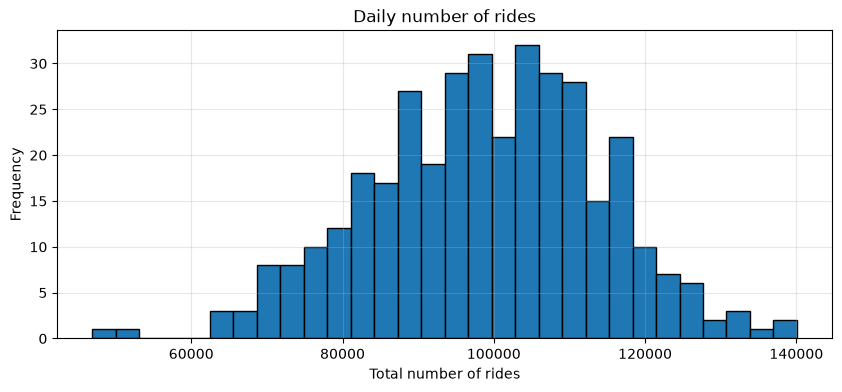

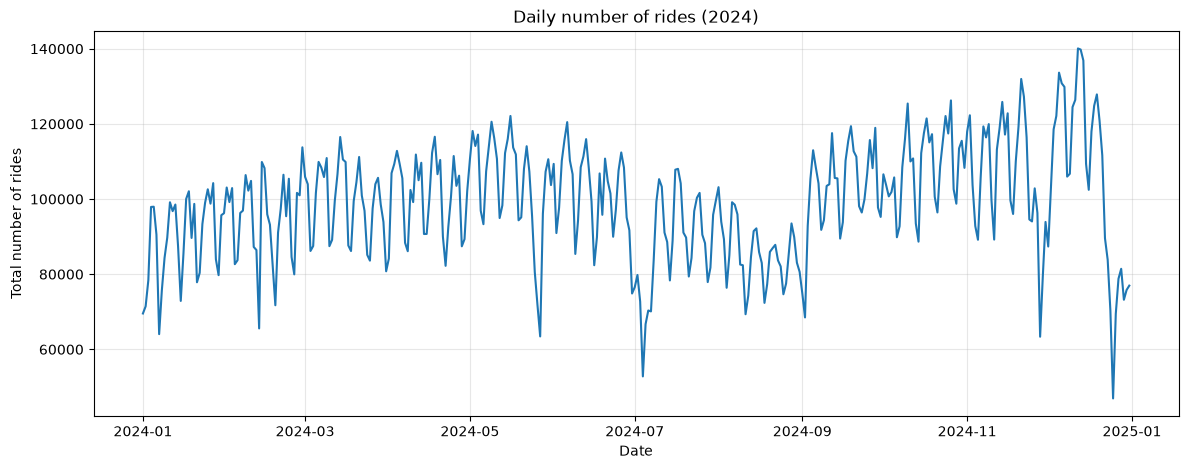

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.hist(daily_df["total_number_of_rides"], bins=30, edgecolor="black")
plt.title("Daily number of rides")
plt.xlabel("Total number of rides")
plt.ylabel("Frequency")
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(14, 5))
plt.plot(daily_df["date"], daily_df["total_number_of_rides"], color="tab:blue", linewidth=1.5)
plt.title("Daily number of rides (2024)")
plt.xlabel("Date")
plt.ylabel("Total number of rides")
plt.grid(True, alpha=0.3)
plt.show()